# PHQ-9 IRT Model — Simple Version

**Project:** Student Mental Health Early Warning System  
**Assessment:** PHQ-9 / Depression only

This notebook trains a **Graded Response IRT model** using real PHQ-9 student responses and then estimates an IRT-based score for a new student's nine answers.

> **Important:** The conventional PHQ-9 grading shown later is **reference only**. It is NOT used to train the IRT model and NOT used to create the final project score.

```text
Real PHQ-9 data
      ↓
Data checks
      ↓
Graded Response IRT
      ↓
Learn item parameters
      ↓
Estimate student's theta
      ↓
Convert theta to 0–10 project indicator
```

## 1. Install packages

Run this only if something is missing.

In [1]:
# %pip install pandas numpy scipy matplotlib joblib

## 2. Import libraries

In [5]:
from pathlib import Path
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import norm

print("Libraries loaded.")


Libraries loaded.


## 3. Load the PHQ-9 dataset

Expected structure:

```text
Minor Project 1/
├── PHQ9_Real_24292_Annotated_Questions.csv
└── models/
    └── PHQ9_IRT_Simple.ipynb
```


In [8]:
DATA_PATH = Path("PHQ9_Real_24292_Annotated_Questions.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)

print("Rows:", len(df))
print("Columns:", len(df.columns))
display(df.head())


Rows: 24292
Columns: 20


,export_id,score,Q01 — Little interest or pleasure in doing things,time1,"Q02 — Feeling down, depressed, or hopeless",time2,"Q03 — Trouble falling or staying asleep, or sleeping too much",time3,Q04 — Feeling tired or having little energy,time4,Q05 — Poor appetite or overeating,time5,Q06 — Feeling bad about yourself—or that you are a failure or have let yourself or your family down,time6,"Q07 — Trouble concentrating on things, such as reading the newspaper or watching television",time7,Q08 — Moving or speaking so slowly that other people could have noticed? Or the opposite—being so fidgety or restless that you have been moving around a lot more than usual,time8,Q09 — Thoughts that you would be better off dead or of hurting yourself in some way,time9
0,61793,0,0,2.47,0,1.23,0,1.12,0,1.73,0,4.74,0,1.32,0,0.16,0,12.99,0,4.00
1,61809,0,0,8.22,0,7.08,0,1.24,0,1.08,0,1.77,0,1.26,0,1.05,0,2.07,0,3.76
2,61737,0,0,1.88,0,1.65,0,1.00,0,1.18,0,0.81,0,1.29,0,4.17,0,1.29,0,4.58
3,61738,0,0,1.74,0,2.02,0,2.26,0,0.76,0,0.59,0,0.62,0,0.54,0,0.71,0,3.37
4,61739,2,1,5.54,0,2.57,0,1.30,0,2.19,0,1.08,1,3.33,0,3.13,0,3.63,0,4.31


## 4. Select the nine PHQ-9 questions

The `score` column is kept only for a data-quality/reference check. It is **not used as the target** for IRT.

In [9]:
QUESTION_COLS = [
    c for c in df.columns
    if re.match(r"^Q0[1-9] — ", str(c))
]

if len(QUESTION_COLS) != 9:
    raise ValueError(f"Expected 9 PHQ-9 item columns, found {len(QUESTION_COLS)}")

X = df[QUESTION_COLS].astype(int)

for i, col in enumerate(QUESTION_COLS, 1):
    print(f"Q{i}: {col.split(' — ', 1)[1]}")

print("\nResponse values:")
for i, col in enumerate(QUESTION_COLS, 1):
    print(f"Q{i}: {sorted(X[col].unique())}")


Q1: Little interest or pleasure in doing things
Q2: Feeling down, depressed, or hopeless
Q3: Trouble falling or staying asleep, or sleeping too much
Q4: Feeling tired or having little energy
Q5: Poor appetite or overeating
Q6: Feeling bad about yourself—or that you are a failure or have let yourself or your family down
Q7: Trouble concentrating on things, such as reading the newspaper or watching television
Q8: Moving or speaking so slowly that other people could have noticed? Or the opposite—being so fidgety or restless that you have been moving around a lot more than usual
Q9: Thoughts that you would be better off dead or of hurting yourself in some way

Response values:
Q1: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Q2: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Q3: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Q4: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Q5: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Q6: [np.int64(0), np.int64(1), np

## 5. Basic data checks

We check missing values, exact duplicates, invalid responses, and whether the published total equals the nine responses added together.

In [10]:
print("Missing values:", int(X.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))

invalid = ~X.isin([0, 1, 2, 3]).all(axis=1)
print("Invalid response rows:", int(invalid.sum()))

calculated_score = X.sum(axis=1)
score_mismatch = calculated_score != df["score"]
print("Score mismatches:", int(score_mismatch.sum()))

if invalid.any() or score_mismatch.any():
    raise ValueError("Data-quality check failed.")

print("Data check passed.")


Missing values: 0
Exact duplicate rows: 0
Invalid response rows: 0
Score mismatches: 0
Data check passed.


## 6. Conventional PHQ-9 grading — REFERENCE ONLY

This section is only for displaying the normal PHQ-9 result in the notebook.

**It is not used by the IRT model and will not be used for the final project score.**

```text
0–4     Minimal
5–9     Mild
10–14   Moderate
15–19   Moderately severe
20–27   Severe
```

score
Minimal              16886
Mild                  6090
Moderate               957
Moderately severe      262
Severe                  97
Name: count, dtype: int64


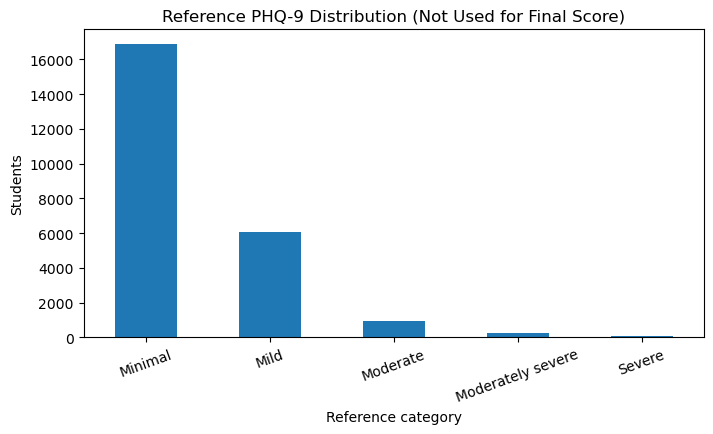

In [11]:
def reference_phq9_level(score):
    if score <= 4:
        return "Minimal"
    elif score <= 9:
        return "Mild"
    elif score <= 14:
        return "Moderate"
    elif score <= 19:
        return "Moderately severe"
    else:
        return "Severe"

reference_levels = df["score"].apply(reference_phq9_level)

print(reference_levels.value_counts().reindex(
    ["Minimal", "Mild", "Moderate", "Moderately severe", "Severe"]
))

plt.figure(figsize=(8, 4))
reference_levels.value_counts().reindex(
    ["Minimal", "Mild", "Moderate", "Moderately severe", "Severe"]
).plot(kind="bar")
plt.title("Reference PHQ-9 Distribution (Not Used for Final Score)")
plt.xlabel("Reference category")
plt.ylabel("Students")
plt.xticks(rotation=20)
plt.show()


## 7. Graded Response IRT

Each PHQ-9 item has four ordered responses:

```text
0 = Not at all
1 = Several days
2 = More than half the days
3 = Nearly every day
```

The IRT model learns:

- **discrimination (`a`)** — how strongly an item separates different levels of the latent trait
- **thresholds (`b`)** — where response-category transitions occur

The model does **not** use the PHQ-9 total score as a target.

In [12]:
THETA_GRID = np.linspace(-4, 4, 81)
QUAD_WEIGHTS = norm.pdf(THETA_GRID)
QUAD_WEIGHTS = QUAD_WEIGHTS / QUAD_WEIGHTS.sum()

responses = X.to_numpy(dtype=int)

print("Training response matrix:", responses.shape)


Training response matrix: (24292, 9)


## 8. Train the IRT model

In [ ]:
def ordered_thresholds(raw):
    first = raw[0]
    inc1 = np.exp(raw[1])
    inc2 = np.exp(raw[2])
    return np.array([first, first + inc1, first + inc1 + inc2])


def category_probabilities(theta, a, thresholds):
    """Return probabilities for response categories 0, 1, 2, 3."""
    theta = np.asarray(theta)
    p_ge = expit(a * (theta[:, None] - thresholds[None, :]))

    p0 = 1 - p_ge[:, 0]
    p1 = p_ge[:, 0] - p_ge[:, 1]
    p2 = p_ge[:, 1] - p_ge[:, 2]
    p3 = p_ge[:, 2]

    return np.column_stack([p0, p1, p2, p3])


def unpack_parameters(params):
    a = np.exp(params[:9])
    thresholds = []

    start = 9
    for _ in range(9):
        thresholds.append(ordered_thresholds(params[start:start + 3]))
        start += 3

    return a, np.array(thresholds)


def negative_log_likelihood(params, responses):
    a, thresholds = unpack_parameters(params)

    log_like = np.zeros((len(responses), len(THETA_GRID)))

    for item in range(9):
        probs = category_probabilities(
            THETA_GRID,
            a[item],
            thresholds[item]
        )

        selected = probs[:, responses[:, item]].T
        log_like += np.log(np.clip(selected, 1e-12, 1.0))

    max_log = log_like.max(axis=1)
    marginal = np.exp(max_log) * np.sum(
        np.exp(log_like - max_log[:, None]) * QUAD_WEIGHTS,
        axis=1
    )

    return -np.sum(np.log(marginal + 1e-300))


initial = []

for _ in range(9):
    initial.append(np.log(1.0))
    initial.extend([-1.0, np.log(1.0), np.log(1.0)])

initial = np.array(initial)

print("Training started...")

result = minimize(
    negative_log_likelihood,
    initial,
    args=(responses,),
    method="L-BFGS-B",
    options={"maxiter": 250, "ftol": 1e-6}
)

print("Training finished.")
print("Success:", result.success)
print("Message:", result.message)

a_params, b_params = unpack_parameters(result.x)

print("\nLearned item parameters:")
for i in range(9):
    print(
        f"Q{i+1}: a={a_params[i]:.3f}, "
        f"thresholds={np.round(b_params[i], 3)}"
    )


Training started...


## 9. Estimate a student's IRT theta

After training, the model can estimate the latent trait for a new student's nine answers.

We use **EAP (Expected A Posteriori)** estimation.

In [ ]:
def estimate_theta_eap(answer_list):
    """Estimate theta from exactly nine PHQ-9 answers."""
    answers = np.asarray(answer_list, dtype=int)

    if answers.shape != (9,):
        raise ValueError("Exactly 9 answers are required.")

    if not np.isin(answers, [0, 1, 2, 3]).all():
        raise ValueError("Each answer must be 0, 1, 2, or 3.")

    log_like = np.zeros(len(THETA_GRID))

    for item in range(9):
        probs = category_probabilities(
            THETA_GRID,
            a_params[item],
            b_params[item]
        )

        log_like += np.log(
            np.clip(probs[:, answers[item]], 1e-12, 1.0)
        )

    posterior = np.exp(log_like - log_like.max()) * QUAD_WEIGHTS
    posterior = posterior / posterior.sum()

    return float(np.sum(THETA_GRID * posterior))


print("Theta estimation function is ready.")


## 10. Convert theta to the project 0–10 indicator

This is **not the conventional PHQ-9 score**.

We convert the IRT latent trait to a bounded 0–10 project indicator using the normal CDF:

```text
theta → normal CDF → 0–1 → ×10 → 0–10
```

This is kept separate from the conventional PHQ-9 grading.

In [ ]:
def theta_to_project_score(theta):
    # IRT latent trait -> bounded 0-10 project indicator.
    return float(10 * norm.cdf(theta))


example_answers = [2, 1, 3, 2, 0, 1, 2, 0, 0]

theta = estimate_theta_eap(example_answers)
project_score = theta_to_project_score(theta)

print("Example answers:", example_answers)
print(f"IRT theta: {theta:.3f}")
print(f"Project IRT indicator: {project_score:.2f} / 10")


## 11. Function for a new student

This is the part that can eventually be connected to the FastAPI backend.

In [ ]:
def predict_phq9_irt(answer_list):
    theta = estimate_theta_eap(answer_list)
    score_10 = theta_to_project_score(theta)

    return {
        "theta": round(theta, 4),
        "irt_score_10": round(score_10, 2)
    }


new_student_answers = [1, 2, 2, 1, 0, 1, 2, 0, 0]

print(predict_phq9_irt(new_student_answers))


## 12. Save the trained model

The website will load these learned parameters. It will **not retrain the IRT model for every student**.

In [ ]:
MODEL_PATH = Path("phq9_irt_model.joblib")

model_data = {
    "question_columns": QUESTION_COLS,
    "theta_grid": THETA_GRID,
    "quadrature_weights": QUAD_WEIGHTS,
    "discrimination": a_params,
    "thresholds": b_params,
    "score_method": "IRT theta -> 10 * normal_cdf(theta)",
    "reference_phq9_grading_used_for_final_score": False
}

joblib.dump(model_data, MODEL_PATH)

print("Saved model:", MODEL_PATH.resolve())


# Final understanding

### Training

```text
24,292 real student responses
        ↓
Graded Response IRT
        ↓
Learn item parameters
        ↓
IRT theta scale
```

### New student

```text
9 answers
   ↓
trained IRT model
   ↓
theta
   ↓
0–10 project IRT indicator
```

### Important

The normal PHQ-9 0–27 grading shown earlier is **only a reference/check**.

It is **not the final scoring system**.

The final project indicator comes from the **IRT latent trait**.
